In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("/content/House_Price_dataset.csv")
df = df[df['purpose']== 'For Sale'].copy()
df['Area'] = df['Area Size']
df.loc[df['Area Type'] == 'kanal','Area'] = df['Area Size'] * 20

df = df[(df['Area']>0) & (df['price']>0)]
df = df[(df['Area']< df['Area'].quantile(0.99)) & (df['price']<df['price'].quantile(0.99))]
df = df.sample(n=2000,random_state=42).copy()

x= df[['Area','price']]
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

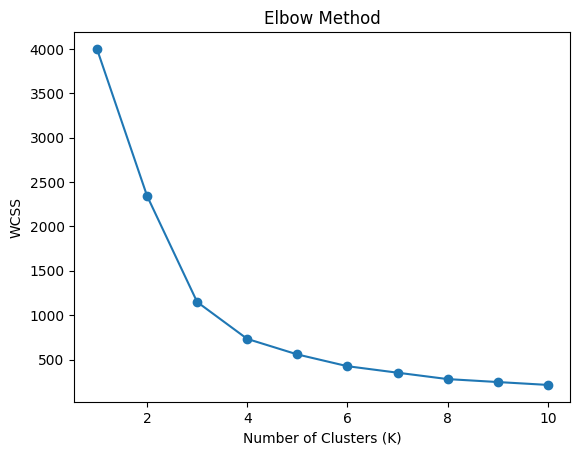

In [6]:
wcss =[]
for k in range(1,11):
  km = KMeans(n_clusters=k,random_state=42,n_init=10)
  km.fit(x_scaled)
  wcss.append(km.inertia_)
plt.plot(range(1,11),wcss,marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [11]:
kmeans = KMeans(n_clusters=4,random_state=42,n_init=10)
df['Cluster'] = kmeans.fit_predict(x_scaled)

print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area','price']].mean())

Cluster
0     574
1    1135
2     224
3      67
Name: count, dtype: int64
             Area         price
Cluster                        
0        9.658362  2.388223e+07
1        4.350749  8.524071e+06
2        1.160714  5.028571e+07
3        1.568657  1.271642e+08


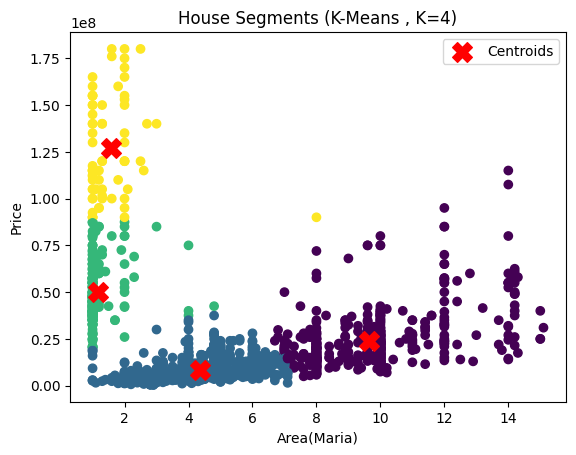

In [13]:
plt.scatter(df['Area'],df['price'],c=df['Cluster'],cmap='viridis')
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:,0],centers[:,1],c='red',marker='X',s=200,label='Centroids')
plt.xlabel('Area(Maria)');plt.ylabel('Price')
plt.title('House Segments (K-Means , K=4)');plt.legend();plt.show()